In [1]:
from ultralytics import YOLO 
import cv2 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import math

In [2]:
#model = YOLO('/Users/keagonbeatty/Downloads/yolo-retry/runs/obb/train/weights/best.pt')
model = YOLO('/Users/keagonbeatty/Documents/MachineLearning/pattern_pictures/yolo-retry/runs/obb/train/weights/best.pt')

In [3]:
# Load the image
image_path = "/Users/keagonbeatty/Documents/MachineLearning/pattern_pictures/1/rendered_image_91_90_1.png"  # Replace with your image path
image = Image.open(image_path)

# Perform predictions
results = model.predict(image_path, conf=0.5)  # Adjust confidence threshold if needed

# Extract predictions
raw_predictions = results[0].obb.xywhr  # Assuming batch size of 1

#print(raw_predictions)
predictions = []
for tens in raw_predictions:
    predictions.append(tens.tolist())

for prediction in predictions:
    print(prediction)


image 1/1 /Users/keagonbeatty/Documents/MachineLearning/pattern_pictures/1/rendered_image_91_90_1.png: 480x640 232.6ms
Speed: 7.4ms preprocess, 232.6ms inference, 6.9ms postprocess per image at shape (1, 3, 480, 640)
[494.7069396972656, 492.537841796875, 157.0545654296875, 68.22101593017578, 1.5853540897369385]
[593.4844360351562, 256.675537109375, 160.5377960205078, 69.34881591796875, 1.5777283906936646]
[495.17010498046875, 302.76409912109375, 158.30355834960938, 66.30300903320312, 1.5793198347091675]
[689.6262817382812, 302.36578369140625, 161.96102905273438, 68.5172348022461, 1.5707136392593384]
[591.4212036132812, 444.54254150390625, 160.43588256835938, 71.2254638671875, 1.571911334991455]
[688.9281005859375, 490.324951171875, 158.89376831054688, 70.55035400390625, 1.573449969291687]
[397.60406494140625, 444.56561279296875, 159.47329711914062, 67.15391540527344, 1.587706208229065]
[398.5696716308594, 255.88442993164062, 165.2239532470703, 67.64274597167969, 1.577422857284546]
[30

In [4]:
print(results[0].obb.xywhr)

tensor([[494.7069, 492.5378, 157.0546,  68.2210,   1.5854],
        [593.4844, 256.6755, 160.5378,  69.3488,   1.5777],
        [495.1701, 302.7641, 158.3036,  66.3030,   1.5793],
        [689.6263, 302.3658, 161.9610,  68.5172,   1.5707],
        [591.4212, 444.5425, 160.4359,  71.2255,   1.5719],
        [688.9281, 490.3250, 158.8938,  70.5504,   1.5734],
        [397.6041, 444.5656, 159.4733,  67.1539,   1.5877],
        [398.5697, 255.8844, 165.2240,  67.6427,   1.5774],
        [303.3454, 302.2315, 159.9685,  69.6126,   1.5763],
        [302.0532, 493.5545, 159.6231,  69.4900,   1.5792]])


/var/folders/4y/c1fxwf455kl9km4k0t93jjr40000gn/T/ipykernel_17188/1543791066.py:17: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)  # Convert to integer coordinates


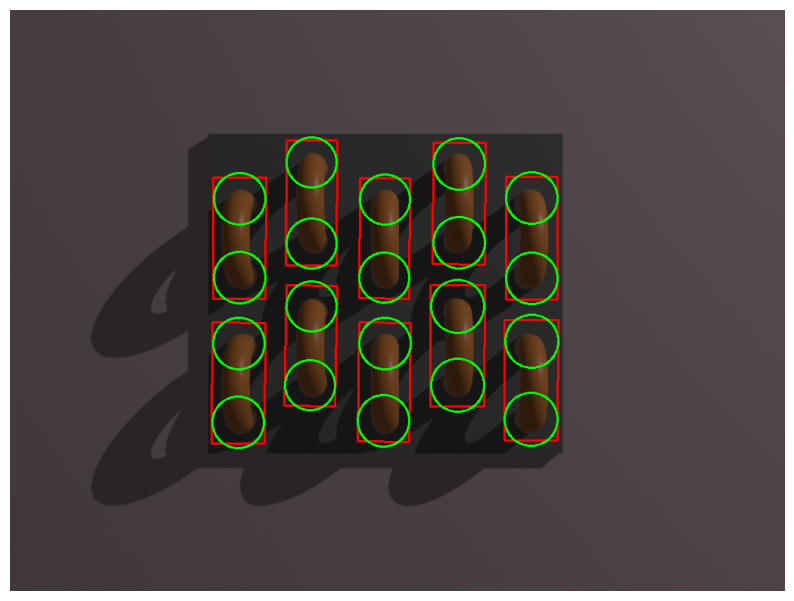

In [5]:
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for display

circles = []
# Iterate over predictions and draw rotated rectangles and circles
for i in range(0, len(predictions)):
#for pred in predictions:
    pred = predictions[i]
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi  # Convert radians to degrees for OpenCV

    # Define the rotated rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    # Get the four corner points of the rotated rectangle
    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)  # Convert to integer coordinates

    # Draw the rotated rectangle
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    # Draw a circle at the center of the bounding box
    circ_x =(np.cos(pred[4]) * ((width * .65) / 2))
    circ_y =(np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    add_circles1 = [int(x_center + circ_x), int(y_center + circ_y), radius, i]
    add_circles2 = [int(x_center - circ_x), int(y_center - circ_y), radius, i]
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)
    circles.append(add_circles1)
    circles.append(add_circles2)

# Display the image with bounding boxes and circles
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()


In [6]:
coordinates = pd.DataFrame(circles, columns=['X', 'Y', 'Radius', 'return_bend'])

In [7]:
divisions = (coordinates['X'].max() - coordinates['X'].min())/5

In [8]:
print(coordinates.sort_values(by='X'))

      X    Y  Radius  return_bend
18  301  545      34            9
19  302  441      34            9
17  303  250      34            8
16  303  354      34            8
12  396  496      33            6
15  398  202      33            7
14  398  309      33            7
13  398  392      33            6
0   493  543      34            0
4   494  354      33            2
5   495  251      33            2
1   495  441      34            0
8   591  496      35            4
9   591  392      35            4
3   593  204      34            1
2   593  308      34            1
10  688  541      35            5
7   689  249      34            3
11  689  438      35            5
6   689  355      34            3


length of circles array: 20


/var/folders/4y/c1fxwf455kl9km4k0t93jjr40000gn/T/ipykernel_17188/2705176325.py:22: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)  # Convert to integer coordinates


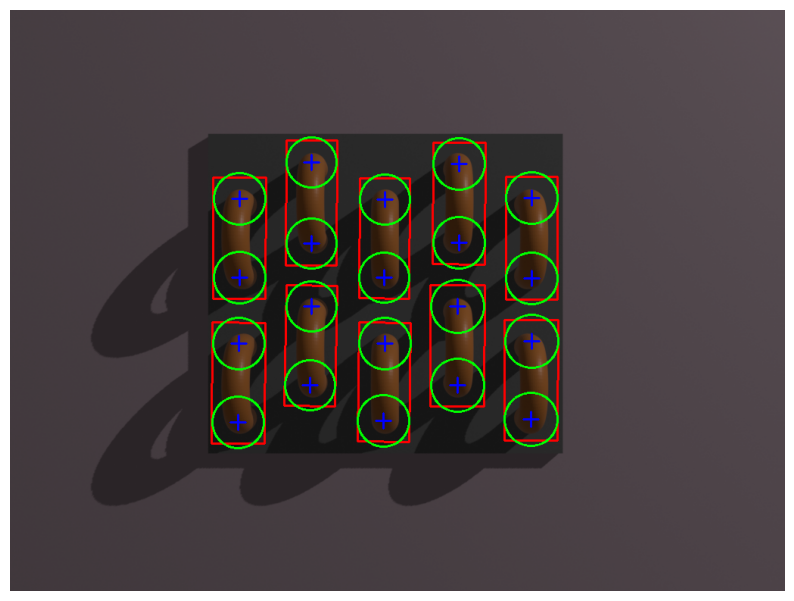

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load the image
image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for display

# Iterate over predictions and draw rotated rectangles and circles
for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi  # Convert radians to degrees for OpenCV

    # Define the rotated rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    # Get the four corner points of the rotated rectangle
    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)  # Convert to integer coordinates

    # Draw the rotated rectangle
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    # Draw a circle at the center of the bounding box
    circ_x =(np.cos(pred[4]) * ((width * .65) / 2))
    circ_y =(np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)

    # Add horizontal lines

for circle in circles:
    cv2.line(image, (circle[0], circle[1]-10), (circle[0], circle[1]+10), color=(0, 0, 255), thickness = 2)
    cv2.line(image, (circle[0]-10, circle[1]), (circle[0]+10, circle[1]), color=(0, 0, 255), thickness = 2)
# Display the image with bounding boxes, circles, and horizontal lines

print(f'length of circles array: {len(circles)}')
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()

In [10]:
x_rows = 5

x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)
x_inter_group_space = x_groups * .25

print(x_groups)

y_rows = 8
y_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)
y_inter_group_space = y_groups * .25

print(y_groups)

97.0
49.0


/var/folders/4y/c1fxwf455kl9km4k0t93jjr40000gn/T/ipykernel_17188/1737663569.py:22: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)  # Convert to integer coordinates


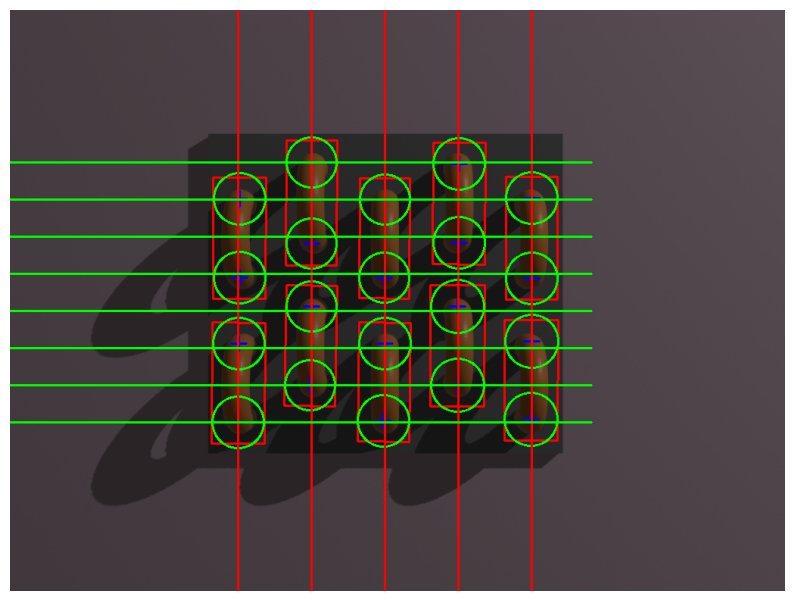

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load the image
image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for display

# Iterate over predictions and draw rotated rectangles and circles
for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi  # Convert radians to degrees for OpenCV

    # Define the rotated rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    # Get the four corner points of the rotated rectangle
    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)  # Convert to integer coordinates

    # Draw the rotated rectangle
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    # Draw a circle at the center of the bounding box
    circ_x = (np.cos(pred[4]) * ((width * .65) / 2))
    circ_y = (np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)


# Add horizontal lines
for circle in circles:
    cv2.line(image, (circle[0], circle[1] - 10), (circle[0], circle[1] + 10), color=(0, 0, 255), thickness=2)
    cv2.line(image, (circle[0] - 10, circle[1]), (circle[0] + 10, circle[1]), color=(0, 0, 255), thickness=2)

for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))  # Ensure y_coord is an integer
    cv2.line(image, (y_coord, 0), (y_coord, image.shape[1]), color=(255, 0, 0), thickness=2)

for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    cv2.line(image, (0, x_coord), (image.shape[0], x_coord), color=(0, 255, 0), thickness=2)


# Display the image with bounding boxes, circles, and horizontal lines
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()


In [12]:

x_group_list=[]
for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    x_group_list.append((y_coord - x_inter_group_space, y_coord + x_inter_group_space))

y_group_list=[]
for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    y_group_list.append((x_coord - y_inter_group_space, x_coord + y_inter_group_space))

print(x_group_list)
print(y_group_list)
    

[(276.75, 325.25), (373.75, 422.25), (470.75, 519.25), (567.75, 616.25), (664.75, 713.25)]
[(189.75, 214.25), (238.75, 263.25), (287.75, 312.25), (336.75, 361.25), (385.75, 410.25), (434.75, 459.25), (483.75, 508.25), (532.75, 557.25)]


In [13]:

# Function to assign groups based on predefined ranges
def assign_group_x(x):
    for i, (min_val, max_val) in enumerate(x_group_list):
        if min_val <= x < max_val:
            return i
    return len(x_group_list)  # Default if value doesn't fit any range

def assign_group_y(y):
    for i, (min_val, max_val) in enumerate(y_group_list):
        if min_val <= y < max_val:
            return i
    return len(y_group_list)  # Default if value doesn't fit any range


In [ ]:
# Apply the function to the 'X' column
coordinates['Group_X'] = coordinates['X'].apply(assign_group_x)
coordinates['Group_Y'] = coordinates['Y'].apply(assign_group_y)

print(coordinates)

      X    Y  Radius  return_bend  Group_X  Group_Y
0   493  543      34            0        2        7
1   495  441      34            0        2        5
2   593  308      34            1        3        2
3   593  204      34            1        3        0
4   494  354      33            2        2        3
5   495  251      33            2        2        1
6   689  355      34            3        4        3
7   689  249      34            3        4        1
8   591  496      35            4        3        6
9   591  392      35            4        3        4
10  688  541      35            5        4        7
11  689  438      35            5        4        5
12  396  496      33            6        1        6
13  398  392      33            6        1        4
14  398  309      33            7        1        2
15  398  202      33            7        1        0
16  303  354      34            8        0        3
17  303  250      34            8        0        1
18  301  545

In [15]:
print(coordinates.sort_values(by='return_bend'))

      X    Y  Radius  return_bend  Group_X  Group_Y
0   493  543      34            0        2        7
1   495  441      34            0        2        5
2   593  308      34            1        3        2
3   593  204      34            1        3        0
4   494  354      33            2        2        3
5   495  251      33            2        2        1
6   689  355      34            3        4        3
7   689  249      34            3        4        1
9   591  392      35            4        3        4
8   591  496      35            4        3        6
10  688  541      35            5        4        7
11  689  438      35            5        4        5
12  396  496      33            6        1        6
13  398  392      33            6        1        4
14  398  309      33            7        1        2
15  398  202      33            7        1        0
16  303  354      34            8        0        3
17  303  250      34            8        0        1
18  301  545

In [16]:
# Your DataFrame
data = coordinates

df = pd.DataFrame(data)

# Group by 'return_bend'
grouped = df.groupby('return_bend')[['Group_X', 'Group_Y']]

# Format the grouped data into the desired string
result = '{' + ','.join(
    '{{{}}}'.format(
        ','.join('{{{},{}}}'.format(row['Group_X'], row['Group_Y']) for _, row in group.iterrows())
    )
    for _, group in grouped
) + '}'

print(result)


{{{2,7},{2,5}},{{3,2},{3,0}},{{2,3},{2,1}},{{4,3},{4,1}},{{3,6},{3,4}},{{4,7},{4,5}},{{1,6},{1,4}},{{1,2},{1,0}},{{0,3},{0,1}},{{0,7},{0,5}}}
